## Imports

In [90]:
import matplotlib.pyplot as plt
import numpy as np
import pickle
from sklearn.metrics import mean_absolute_error 

In [91]:
with open("MNISTsmall.p", "rb") as data_file:
    D = pickle.load(data_file)


with open("A50756_Ficha3_Respostas.p", "rb") as respostas_file:
    respostas = pickle.load(respostas_file)

In [92]:
print(D)
print(D.keys())
print(respostas)

{'data': array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8), 'target': array([0, 0, 0, ..., 9, 9, 9], dtype=uint8), 'DESCR': 'A subset of the MNIST database of handwritten digits.\nThe original database was developed by Yann LeCun, Corinna Cortes, and Chris Burges. \nFor more information check: http://http://yann.lecun.com/exdb/mnist/.\n\nThe MNISTsmall dataset is composed  of 15000 images of 28x28 pixels consisting of handwritten digits 0 to 9.\nThe first 10000 correspond the the training set and the last 5000 to the test data (also accessible via "foldTrain" variable).\nThe data is packed in a dictionary-type object (actually a utils.Bunch object of sklearn):\ndata   --> dxN where N=15000 (the number of examples) and d=784=28x28 (data dimension)\ntarget --> N   labels from 0 to 9 (examples\' classes)\n', 'target_names':

In [93]:
X = D['data']
y = D['target']

print("X shape:", X.shape)
print("Y shape:", y.shape)

X shape: (784, 15000)
Y shape: (15000,)


## 1.

In [94]:
# Filtrar os índices dos primeiros 278 exemplos do dígito "9"
indices_9 = np.where(y == 9)[0][:278]

# Selecionar as colunas correspondentes ao dígito "3"
X_9 = X[:, indices_9]

## a)

In [95]:
cov = np.cov(X_9)

u, W = np.linalg.eig(cov)

u = u.real
W = W.real

# Ordena os autovalores em ordem decrescente e rearranja os autovetores de acordo
idx = np.argsort(-u)
u = u[idx]
W = W[:, idx]

un = u / np.sum(u)

# Calcula a variância explicada acumulada
L = np.cumsum(un)

# Encontrar o número mínimo de componentes para ter mais de 65% da variância
num_components = np.argmax(L > 0.85) + 1  
# Adicionar 1 porque a indexação começa em 0

print(f"Resposta: {num_components}")

respostas['Q001'][0,:] = [0,0,0,1] 
respostas['Q001'][0,:]

Resposta: 33


array([0., 0., 0., 1.])

# b.

#### Para esta alinea, arredonde os valores pedidos a 2 casas decimais.
##### i. Existem 332 dimensoes dos dados que nao variam.
##### ii. O coeficiente de correlaçao entre a dimensao 234 e 465 é 0.06.

In [96]:
variances = np.var(X_9, axis=1)

num_dimensions_zero_variance = np.sum(variances < 1e-10)

print(f"Resposta i: {num_dimensions_zero_variance}")

dim_233 = X_9[233, :]  
dim_464 = X_9[464, :]  

correlation_234_465 = np.corrcoef(dim_233, dim_464)[0, 1]

print(f"Resposta ii: {round(correlation_234_465, 2)}")

respostas['Q001'][1,:] = [0,0,0,1] 
respostas['Q001'][1,:]

Resposta i: 312
Resposta ii: -0.11


array([0., 0., 0., 1.])

# c.
#### Considere que se estima a matriz de covariancia deste conjunto
##### i. A dimensão da matriz é 784 ×784.
##### ii. O determinante da matriz de convariancia não é igual a 0. 

In [97]:
cov_matrix = np.cov(X_9)

print("Resposta i:", cov_matrix.shape)

# Calcular o determinante da matriz de covariância
det_cov_matrix = np.linalg.det(cov_matrix)
print("Resposta ii:", det_cov_matrix)


respostas['Q001'][2,:] = [1,0,0,0] 
respostas['Q001'][2,:]

Resposta i: (784, 784)
Resposta ii: 0.0


array([1., 0., 0., 0.])

# d.

#### Pretende-se visualizar os digitos deste conjunto e os vetores propios da matriz de covariancia dos dados

##### i. A figura de cima ́e a imagem invertida do 53º digito do conjunto.
##### ii. A figura de baixo e a imagem (ou a imagem invertida) do 4º vetor proprio da matriz de covariancia dos dados.

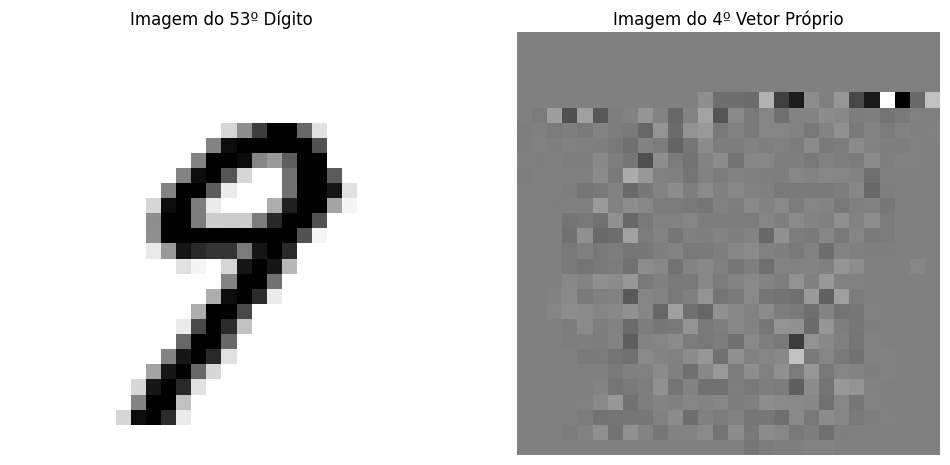

array([1., 0., 0., 0.])

In [98]:
digit_index = 52
digit_image = X_9[:, digit_index].reshape(28, 28)

cov_matrix = np.cov(X_9)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

eigenvector_index = 3  
eigenvector_image = eigenvectors[:, eigenvector_index].reshape(28, 28)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title("Imagem do 53º Dígito")
plt.imshow(digit_image, cmap='binary')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Imagem do 4º Vetor Próprio")
plt.imshow(eigenvector_image, cmap='gray')
plt.axis('off')

plt.show()


respostas['Q001'][3,:] = [1,0,0,0] 
respostas['Q001'][3,:]

# e. 

#### O numero de valores proprios superiores a 10^−10 da matriz de covariancia dos dados é:

In [99]:
cov_matrix = np.cov(X_9)

eigenvalues, _ = np.linalg.eigh(cov_matrix) 

eigenvalues_significant = eigenvalues[eigenvalues > 1e-10]

num_eigenvalues_significant = len(eigenvalues_significant)

print(f"Resposta: {num_eigenvalues_significant}")

respostas['Q001'][4,:] = [0,0,1,0] 
respostas['Q001'][4,:]


Resposta: 277


array([0., 0., 1., 0.])

# e.

#### Para esta alinea, arredonde os valores pedidos a 0 casas decimais. Considere que os 123º, 205º, 227º e 260º digitos sao representados pelos vetores x1,x2,x3,e x4.

##### i. O produto interno entre os vetores x1 e x2  ́e 2 601 954.
##### ii. O produto interno entre os vetores x3 e x4  ́e 1 980 417.

In [100]:
indices = [122, 204, 226, 259] 

# Obter os vetores correspondentes aos dígitos
x1 = X_9[:, indices[0]]*1.0
x2 = X_9[:, indices[1]]*1.0
x3 = X_9[:, indices[2]]*1.0
x4 = X_9[:, indices[3]]*1.0

# Calcular o produto interno entre x1 e x2, e x3 e x4
inner_product_x1_x2 = np.dot(x1, x2)
inner_product_x3_x4 = np.dot(x3, x4)

print(f"Resposta i: {np.round(inner_product_x1_x2, 0)}")
print(f"Resposta ii: {np.round(inner_product_x3_x4, 0)}")
print()
print(f"Resposta i: {np.round(inner_product_x1_x2, 0) == 2601954}")
print(f"Resposta ii: {np.round(inner_product_x3_x4, 0) == 1980417}")

respostas['Q001'][5,:] = [0,1,0,0] 
respostas['Q001'][5,:]

Resposta i: 3902400.0
Resposta ii: 1980417.0

Resposta i: False
Resposta ii: True


array([0., 1., 0., 0.])

In [101]:
with open("A50756_Ficha3_Respostas.p", 'wb') as file:
    pickle.dump(respostas, file)

print(respostas['Q001'])

[[0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]]
